In [ ]:
import os
import sys
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, timezone

from Legacy.Binance_new import Binance # Get_Price_Data_By_Time

from RL_Indicators import normalize, get_level, get_change, get_volatility
from RL_Market_History import Market_History

from RL_Trade_POC_Util import plot_arrays

In [2]:
bn = Binance.instantiate(connect=False)

Initializing Binance singleton...


In [3]:
# Get_Price_Data_By_Time function seamlessly collects/creates price candles from Binance.
datatype = "klines" # "aggTrades" #, "klines"
symbol = "BTCUSDT"      # Any pair listed on Binance.

# dates that worked
# start = datetime(2018, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
# end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

start = datetime(2025, 7, 12)    # Any datetime. Note Binance started operation in July 2017.
end = datetime(2026, 2, 26) # + timedelta(minutes=100)     # Any datetime

interval = '1m'    # in '1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '6h', '8h', '12h', '1d'.  (excludes: '3d', '1w')
print(f"interval: {interval}")
#------------------------------------------------------------------------------------------------------------------
candles, nFills, successful, _, reason = bn.Get_Price_Data_By_Time(datatype, symbol, interval, start, end)
print(reason)
if successful:          # price is a numpy array.
    print("\n Successful !!!!!!!!!! (nCandles, nAttributes) = {}, nCreated = {}".format(candles.shape, nFills))

interval: 1m
nCreated/nTotal/expected 0/329760/329760. 
Returning 10 columns: O H L C V, Quote V, nTrades, Buy base V, Buy quote V, Mark (0: original not forged)


 Successful !!!!!!!!!! (nCandles, nAttributes) = (329760, 10), nCreated = 0


In [4]:
marks = candles[:, 9]
z_marks = marks[marks == 0]
print(len(marks), len(z_marks), len(marks) -  len(z_marks))

329760 329760 0


In [5]:
n = 500

x = candles[:n, 3]      # close
v = candles[:n, 4]      # volume
x_normal = normalize(x, axis=0) * 2
v_normal = normalize(v, axis=0) * 2
lookback = 30           # we look lookback as far as 'lookback'

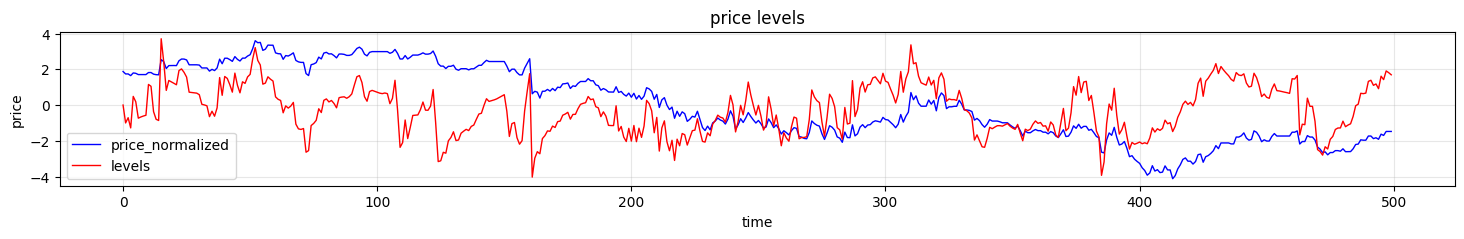

In [6]:

levels = []
for anchor in range(x.shape[0]):
    level = get_level(x, anchor, lookback, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([x_normal, levels], labels=['price_normalized', 'levels'], title="price levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

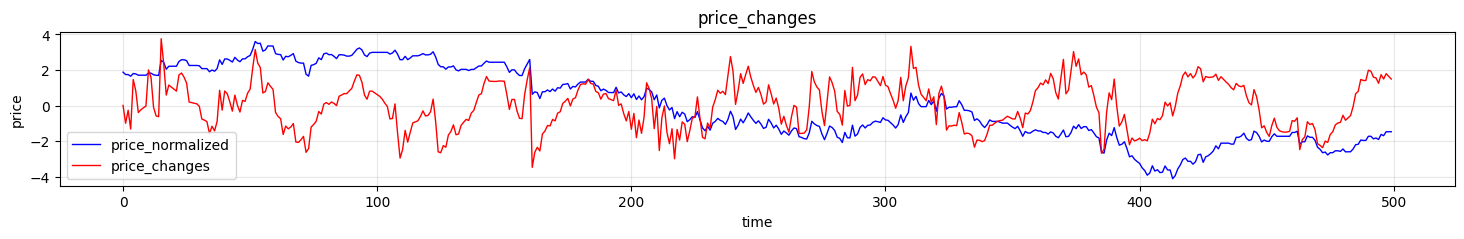

In [7]:
price_changes = []
for anchor in range(x.shape[0]):
    pc = get_change(x, anchor, lookback, axis=0)
    price_changes.append(pc)
price_changes = np.array(price_changes)
assert price_changes.shape == x.shape

plot_arrays([x_normal, price_changes], labels=['price_normalized', 'price_changes'], title="price_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


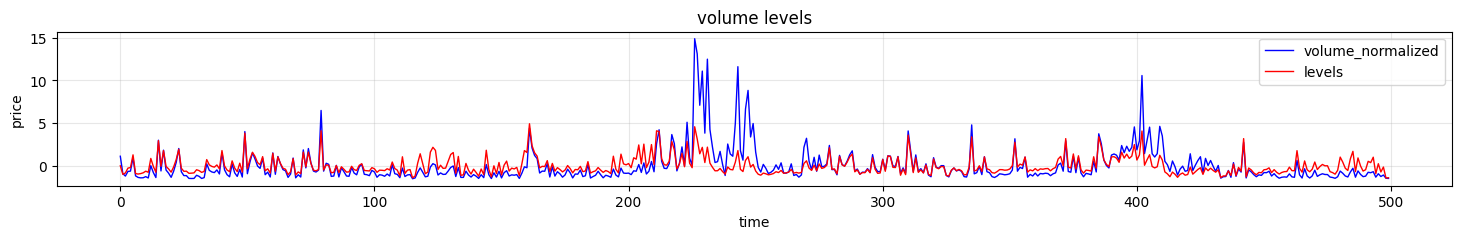

In [8]:
levels = []
for anchor in range(x.shape[0]):
    level = get_level(v, anchor, lookback, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([v_normal, levels], labels=['volume_normalized', 'levels'], title="volume levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

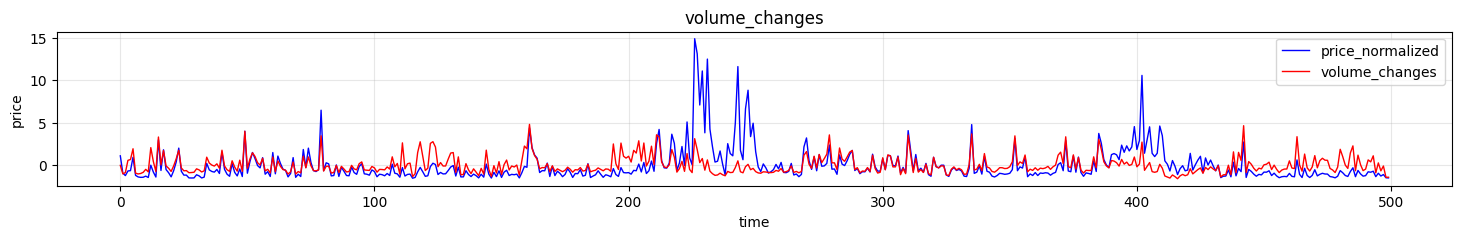

In [9]:
volume_changes = []
for anchor in range(v.shape[0]):
    vc = get_change(v, anchor, lookback, axis=0)
    volume_changes.append(vc)
volume_changes = np.array(volume_changes)
assert volume_changes.shape == v.shape

plot_arrays([v_normal, volume_changes], labels=['price_normalized', 'volume_changes'], title="volume_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


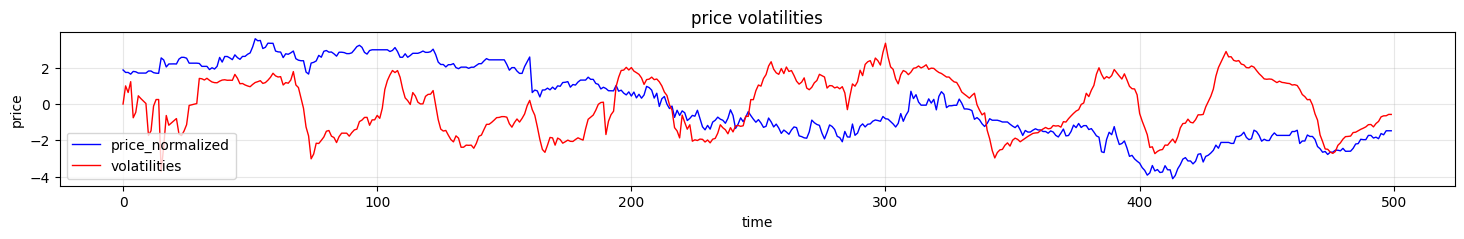

In [10]:
volatilities = []
for anchor in range(x.shape[0]):
    volatility = get_volatility(x, anchor, lookback, axis=0, span=lookback)
    volatilities.append(volatility)
volatilities = np.array(volatilities)
assert volatilities.shape == x.shape

plot_arrays([x_normal, volatilities], labels=['price_normalized', 'volatilities'], title="price volatilities", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


In [11]:

from enum import Enum
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class Action(Enum):
    Hold = 0
    Sell = 1
    Buy = -1
    
max_buys = 30
back_price_features = 300

#-------- min_arr_len_to_compress decided by back_price_features --------
nodes = [ ((k) * math.log(k) - k) / math.log(2) for k in range(1, back_price_features + 4) ]
compress_kernel = [((nodes[i-1]+nodes[i])/2, (nodes[i]+nodes[i+1])/2) for i in range(1, back_price_features + 2)]
assert len(compress_kernel) == back_price_features + 1
min_arr_len_to_compress = math.ceil(compress_kernel[-1][1]) + 1


state_features = back_price_features + 5 + max_buys     # 5 indicators
print(f"state_features {state_features}")
    
def get_reward(action, price_curr, buy_costs):
    would_sell_revenue = len(buy_costs) * price_curr
    total_cost = sum(buy_costs)
    would_sell_profit = would_sell_revenue - total_cost
    # print(f"would_sell_profit {would_sell_profit}")
    sell_reward = -1 if len(buy_costs) == 0 else (-1 if would_sell_profit <= 0 else 1)      # -1 if would_sell_profit <= 0 ---- think of fees
    dict = { Action.Buy: 0, Action.Hold: 0, Action.Sell: sell_reward}
    reward = dict[action]
    return reward

def get_state(environment, buy_costs):
    prices, volumes, price_curr = environment
    price_state = prices[- back_price_features :].tolist()     #----------------------- Consider introducing compressed history. No need to flip.
    assert len(price_state) == back_price_features
    price_state = np.array(price_state)
    price_state = price_state / price_state.mean()
 
    indicator_state = []   
    indicator_state.append(get_level(prices, len(prices)-1, lookback, axis=0))
    indicator_state.append(get_change(prices, len(prices)-1, lookback, axis=0))
    indicator_state.append(get_level(volumes, len(prices)-1, lookback, axis=0))
    indicator_state.append(get_change(volumes, len(prices)-1, lookback, axis=0))
    indicator_state.append(get_volatility(prices, len(prices)-1, lookback, span=lookback))
    indicator_state = np.array(indicator_state)

    buy_state = []    
    assert len(buy_costs) <= max_buys
    buy_state = buy_costs + [0 for _ in range(max_buys - len(buy_costs))]
    buy_state = np.array(buy_state)

    state = np.concat([price_state, indicator_state, buy_state])
    state = torch.from_numpy(state).float()
    assert state.shape[-1] == state_features
    state = state.unsqueeze(0)  # (batch, state_features)
    return state

    price_curr = prices[-1]
def take_action(action, environment, buy_costs, buy_unit=1):
    prices, volumes, price_curr = environment
    reward = get_reward(action, price_curr, buy_costs)
    state = get_state(environment, buy_costs)
    done = action == Action.Sell

    cash_in, cash_out, fee = 0, 0, 0
    if action == Action.Buy:
        if len(buy_costs) < max_buys:
            cash_out += price_curr * buy_unit
            buy_costs.append(cash_out)
    elif action == Action.Sell:
        cash_in += len(buy_costs) * buy_unit * price_curr
        buy_costs = []
    
    assert cash_in <= 0 or cash_out <= 0
    fees = (cash_in + cash_out) * 0.0  #0075

    net_cash_in = cash_in - cash_out - fees
    
    state_next = get_state(environment, buy_costs)
    
    return reward, state_next, done, buy_costs, net_cash_in


state_features 335


In [12]:
import random

buy_costs = []
actions = [Action.Buy] * 3 + [Action.Hold] * 10 + [Action.Sell] * 1

reward_history = []
inventory_value_history = []
cash_balance_history, cash_balance = [], 0

ext_lookback = max(3 * lookback - 2, min_arr_len_to_compress)     # back_price_features: tight

In [13]:

class PositionwiseFeedForward(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, 
                 act_layer=nn.GELU, drop=0., depth=1):
        
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        
        layers = []
        
        # First layer: input to hidden
        layers.append(nn.Linear(in_features, hidden_features))
        layers.append(act_layer())
        layers.append(nn.Dropout(drop))
        
        # Intermediate hidden layers (if depth > 1)
        for _ in range(depth - 1):
            layers.append(nn.Linear(hidden_features, hidden_features))
            layers.append(act_layer())
            layers.append(nn.Dropout(drop))
        
        # Final layer: hidden to output
        layers.append(nn.Linear(hidden_features, out_features))
        
        self.net = nn.Sequential(*layers)
        
    def forward(self, x, ss=None):
        return self.net(x)
    
class ActionValue(nn.Module):
    def __init__(self, state_features, hidden_features, nAcitons, depth=1):
        super().__init__()
        self.ffn = PositionwiseFeedForward(state_features, hidden_features, out_features=nAcitons, act_layer=nn.GELU, depth=depth)
        
    def forward(self, state):
        ffn_out = self.ffn(state)      # scaled for faster training. expected value in {-1, +1}
        return ffn_out

Q_model = ActionValue(20, 50, 3, 2)
state = torch.tensor([1.2] * 20).unsqueeze(0)
with torch.set_grad_enabled(False):
    q = Q_model(state).squeeze(0)
print(q)

tensor([ 0.1015, -0.1497,  0.2322])


In [14]:
def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # For PyTorch 1.10+
    if hasattr(torch, 'use_deterministic_algorithms'):
        torch.use_deterministic_algorithms(True)

In [15]:
mh = Market_History(dim_compact_history=300, indicator_window=30)

prices_compressed (300,)


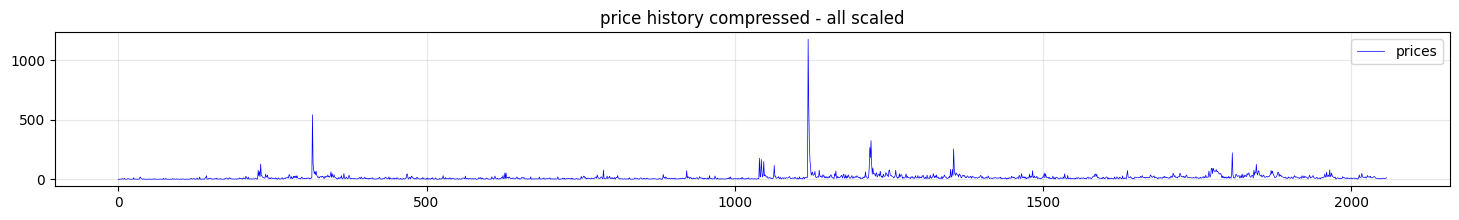

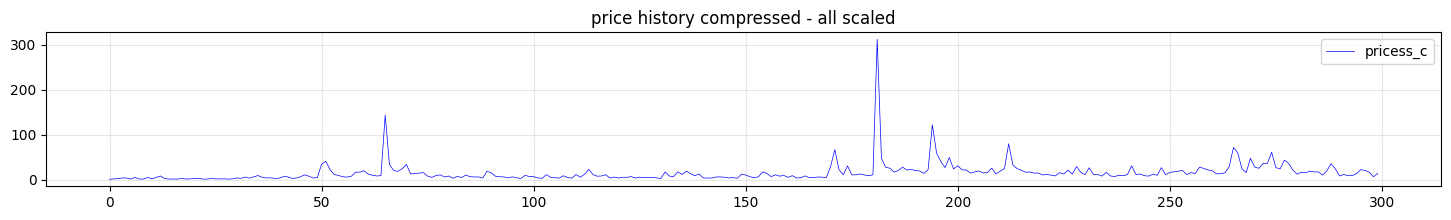

In [16]:
anchor = 3500
prices = candles[anchor - min_arr_len_to_compress + 1 : anchor + 1, 4]
prices_compressed = mh.compress_hitorical_sequence_preserve_last(prices)
print(f"prices_compressed {prices_compressed.shape}")

plot_arrays([prices], ['prices'], title="price history compressed - all scaled", xlabel="", ylabel="", figsize=(18, 2), flip=False, lw=0.5)

plot_arrays([prices_compressed], ['pricess_c'], title="price history compressed - all scaled", xlabel="", ylabel="", figsize=(18, 2), flip=False, lw=0.5)

In [17]:

action_list = list(Action)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Initialize Q-network and Target network
Q_model = ActionValue(state_features, hidden_features=state_features * 4, 
                      nAcitons=len(action_list), depth=7).to(device)
base_Q_model = ActionValue(state_features, hidden_features=state_features * 4,
                       nAcitons=len(action_list), depth=7).to(device)

base_Q_model.load_state_dict(Q_model.state_dict())

Q_model.train()
base_Q_model.eval()  # Target network in evaluation mode

action_distribution = [Action.Buy] * 20 + [Action.Hold] * 10 + [Action.Sell] * 10   #------------ Bearish

close_idx, volume_idx, mark_idx = 3, 4, 9   # Decided by Binance_new.py
env_len = len(candles[:, close_idx])
forget_len = np.count_nonzero(candles[:, mark_idx]) # Forged candles are marked non-zero
print(f"forged/total: {forget_len}/{env_len}")

# Learning rate - alpha is handled by optimizer, not in update rule
optimizer = torch.optim.AdamW(Q_model.parameters(), lr=1e-4)

normal_prices = candles[:, close_idx]
normal_volumes = candles[:, volume_idx]
normal_prices = mh.abs_normalize(normal_prices)
normal_volumes = mh.abs_normalize(normal_volumes)
true_prices =candles[:, close_idx]

Using device: cuda
forged/total: 0/329760


In [18]:
train_step_count = 0

def train_with_experiences(experiences, gamma, batch_size, dual_net, base_update_freq):
    #-------------- Training: Update Q_model a bit by using experiences  ------------------             
    global train_step_count
            
    batch_size = min(len(experiences), batch_size)
    if batch_size == 0:
        return None

    # Sample mini-batch
    batch = random.sample(experiences, batch_size)
    
    states_batch, actions_batch, rewards_batch, next_states_batch, dones_batch = [], [], [], [], []

    for state, action, reward, state_next, done in batch:
        # Ensure tensors are on the same device
        if state.device != device:
            state = state.to(device)
        if state_next.device != device:
            state_next = state_next.to(device)
            
        # Flatten to (state_features,) if it's (1, state_features)
        if state.dim() == 2 and state.shape[0] == 1:
            state = state.squeeze(0)
        if state_next.dim() == 2 and state_next.shape[0] == 1:
            state_next = state_next.squeeze(0)
        
        states_batch.append(state)
        actions_batch.append(action_list.index(action))
        rewards_batch.append(reward)
        next_states_batch.append(state_next)
        dones_batch.append(done)

    # Stack to create batch dimension
    states_batch = torch.stack(states_batch, dim=0).to(device)
    actions_batch = torch.tensor(actions_batch, device=device).unsqueeze(1)
    rewards_batch = torch.tensor(rewards_batch, device=device).unsqueeze(1)
    next_states_batch = torch.stack(next_states_batch, dim=0).to(device)
    dones_batch = torch.tensor(dones_batch, device=device).unsqueeze(1)
    
    with torch.enable_grad():
        # Compute current Q values
        pred_q_s_a = Q_model(states_batch).gather(1, actions_batch)
    
    # Compute target Q values using TARGET network
    with torch.no_grad():
        if dual_net:
            q_next_s_max = base_Q_model(next_states_batch).max(1, keepdim=True)[0]
        else:
            q_next_s_max = Q_model(next_states_batch).max(1, keepdim=True)[0]
        
        target_q_s_a = rewards_batch + gamma * q_next_s_max * (~dones_batch)
    
    # Compute loss
    loss = torch.nn.functional.mse_loss(pred_q_s_a, target_q_s_a)
    
    # Optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Update target network
    train_step_count += 1
    if train_step_count % base_update_freq == 0:
        base_Q_model.load_state_dict(Q_model.state_dict())
        if dual_net:
            print(f"Base model updated at step {train_step_count}")
    
    return loss.detach().item()

In [19]:
from collections import deque

def run_eposode(explore_rate, buy_unit=1):
    episode_work_span = 300
    
    experiences, net_cashes_in = deque(maxlen=10000), deque(maxlen=10000)

    #---------------- pick-up episode anchor -----------------    
    while True:
        episode_anchor = random.randint(ext_lookback, env_len - episode_work_span)        
        candlespace = range(episode_anchor - ext_lookback, episode_anchor + episode_work_span)
        if (candles[candlespace, mark_idx]==0).all():
            break
        print(f"Found forged candles. picking another..........................................")
    
    buy_costs, buy_actions, hold_actions, done = [], 0, 0, False

    #--------------- Get initial state -----------------------
    running_anchor = episode_anchor - 1
    environment = mh.compress_history(normal_prices, normal_volumes, true_prices, running_anchor)
    state_next = get_state(environment, buy_costs)
    state_next = state_next.to(device)  # FIX: Move to device immediately
        
    while not done and running_anchor < episode_anchor + episode_work_span:
        state = state_next
        
        #------------- best_action from (Q_model, state) -----------------
        with torch.no_grad():
            q_values = Q_model(state)
            best_action_idx = torch.argmax(q_values[0]).item()
            best_action = action_list[best_action_idx]
        
        #------------- Explore for random action ------------
        if random.random() < explore_rate:
            action = random.choice(action_distribution)
        else:
            action = best_action
        
        #------------- reward, state_next, done from (new environment, action) ------------------- 
        running_anchor += 1
        environment = mh.compress_history(normal_prices, normal_volumes, true_prices, running_anchor)
        reward, state_next, done, buy_costs, net_cash_in = take_action(action, environment, buy_costs, buy_unit=buy_unit)
        state_next = state_next.to(device)  # FIX: Move to device
        net_cashes_in.append(net_cash_in)
        
        if action == Action.Buy: 
            buy_actions += 1
        elif action == Action.Hold: 
            hold_actions += 1
        
        #------------- Store experience ----------------
        experiences.append((state, action, reward, state_next, done))
        
    return experiences, net_cashes_in, buy_actions, hold_actions

In [ ]:
from collections import deque

def train(nEpochs, explore, gamma, batch_size, dual_net=False, base_update_freq=100, buy_unit=1, seed=523):
    set_seed(seed)

    losses, net_cashes_in, total_cash = deque(maxlen=1000), deque(maxlen=1000), 0
    
    for epoch in range(nEpochs):
        decreasing_epoch_explore = max(explore * (1 - epoch / nEpochs), 0.001)
        nEposodes = 10
        
        experiences = deque(maxlen=10000)
        
        for _ in range(nEposodes):
            e_experiences, e_net_cashes_in, buy_actions, hold_actions = run_eposode(decreasing_epoch_explore, buy_unit=buy_unit) 
            experiences = experiences + e_experiences
            
            net_cashes_in = net_cashes_in + e_net_cashes_in
            total_cash += sum(e_net_cashes_in)
            
            print(f"{buy_actions} {hold_actions}, ", end='')
            
        loss = train_with_experiences(experiences, gamma, batch_size, dual_net, base_update_freq)
        
        # Logging
        losses.append(loss)
        
        # Print epoch summary
        ma_loss = sum(losses) / len(losses)
        ma_cash_in = sum(net_cashes_in) / len(net_cashes_in)
        print(f"\nEpoch {epoch}, MA Loss: {ma_loss:.5f}, MA Cash_in: {ma_cash_in:.5f}, total_cash: {total_cash:.2f}")

# Call the function
train(nEpochs=50_000, explore=1, gamma=0.99, batch_size=32, dual_net=False, base_update_freq=100, buy_unit=0.01, seed=4)


3 2, 6 1, 0 0, 0 0, 0 0, 2 0, 0 0, 4 1, 2 2, 3 0, 
Epoch 0, MA Loss: 0.25710, MA Cash_in: 0.20494, total_cash: 7.38
2 2, 5 0, 4 2, 0 2, 1 0, 1 2, 2 0, 0 0, 0 0, 4 1, 
Epoch 1, MA Loss: 0.33592, MA Cash_in: 0.27647, total_cash: 20.46
0 0, 3 0, 2 2, 2 3, 0 0, 5 1, 3 2, 0 1, 0 0, 2 3, 
Epoch 2, MA Loss: 0.32998, MA Cash_in: 0.18727, total_cash: 21.16
0 0, 4 1, 1 3, 0 0, 3 3, 3 0, 0 0, 7 2, 5 0, 6 1, 
Epoch 3, MA Loss: 0.36656, MA Cash_in: 0.13313, total_cash: 21.57
1 0, 1 1, 0 0, 1 0, 1 0, 1 0, 4 1, 1 1, 3 4, 0 0, 
Epoch 4, MA Loss: 0.77286, MA Cash_in: 0.15825, total_cash: 30.38
1 1, 5 1, 5 0, 1 0, 3 4, 4 1, 0 7, 0 0, 0 0, 0 0, 
Epoch 5, MA Loss: 0.98710, MA Cash_in: 0.06302, total_cash: 14.81
2 0, 5 1, 3 0, 3 0, 6 3, 0 0, 1 0, 2 0, 1 0, 0 0, 
Epoch 6, MA Loss: 1.76122, MA Cash_in: 0.05679, total_cash: 15.45
2 0, 7 1, 6 9, 2 1, 4 4, 0 2, 0 2, 0 0, 2 3, 1 1, 
Epoch 7, MA Loss: 3.37343, MA Cash_in: 0.05728, total_cash: 18.84
4 1, 2 0, 1 1, 7 8, 2 2, 5 1, 3 1, 6 1, 1 0, 4 2, 
Epoch 8, MA Lo